# 5. Robustness

**Question.** Which differences between the three barangays survive the ten changes of assumption in section 4.5 of the paper?

**Method.** Every resident is an origin, so there is no sampling error to test. Instead each check recomputes eleven headline metrics for the three barangays: the median resident's walk to each of the nine categories (M1), mean categories within 15 minutes (M4) and the share with convenient transit (M5). A difference between two barangays is a finding only if it keeps its sign in every variant of every check; a gap under 0.05 minutes or categories (one point for M5) is a tie, and a tie is not a finding.

| # | Check | Variants |
|---|---|---|
| 01 | Walking speed | 3.6 and 4.8 km/h |
| 02 | Time threshold | M4 at 5, 10 and 20 minutes |
| 03 | Study area | Residents within 10, 15 and 20 minutes of the barangay's population-weighted centre |
| 04 | Home lens | A 15-minute walk-shed from each home, private (see below) |
| 05 | Distance type | Straight line |
| 06 | Origin resolution | 100 m WorldPop cells and H3 resolution-9 cells, at their centres |
| 07 | Service source | Overture only; OpenStreetMap only (schools by each source's own public-school rule) |
| 08 | Overture confidence | 0.3 and 0.7 |
| 09 | Population surface | GHS-POP in place of WorldPop |
| 10 | Jeepney rule | Mapped stops only, routes not counted |

In [1]:
import sys
from pathlib import Path

# The notebooks import their logic from src/: the shared helpers and the analysis functions.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shared").is_dir())
for folder in ("src/shared", "src/03_analyse"):
    sys.path.insert(0, str(ROOT / folder))

import charts
import measures
import pandas as pd
from common import TABLES
from IPython.display import Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
AREAS = measures.STUDY + ["Metro Manila"]
import sensitivity
import walk_times

w, b = measures.load()
net = walk_times.Network()

In [2]:
rows = sensitivity.check_rows(w, net)
rows.to_csv(TABLES / "sensitivity.csv", index=False, float_format="%.6g")
print(
    "home lens:",
    "run privately, results in data/work/home_lens.csv"
    if rows.attrs["home_lens_ran"]
    else "not run: the private data/manual/homes.csv is not on this machine",
)
rows.pivot_table(index=["check", "variant"], columns=["metric", "barangay"], values="value", sort=False)[
    ["M4", "M5"]
].round(2)

home lens: not run: the private data/manual/homes.csv is not on this machine


metric                             M4                                 M5                      
barangay                 Barangay 136 Loyola Heights Oranbo Barangay 136 Loyola Heights Oranbo
check variant                                                                                 
base  base                       8.74           6.51   7.72         1.00           0.48   0.95
01    3.6 km/h                   7.48           5.86   7.38         1.00           0.48   0.95
      4.8 km/h                   8.95           6.99   8.02         1.00           0.48   0.95
02    5 min                      5.45           1.85   3.81          NaN            NaN    NaN
      10 min                     6.41           4.69   6.75          NaN            NaN    NaN
      20 min                     8.98           7.42   8.29          NaN            NaN    NaN
03    10-min walk-shed           7.76           6.48   7.70         1.00           1.00   1.00
      15-min walk-shed           7.94           6.22   8.33         1.00           0.88   0.97
      20-min walk-shed           8.07           6.66   8.63         1.00           0.94   0.98
05    straight line              9.00           8.73   8.62         1.00           0.85   1.00
06    100 m cells                8.84           6.47   7.81         1.00           0.51   0.96
      H3 resolution 9            8.83           6.82   7.21         0.92           0.46   0.98
07    Overture only              7.74           6.15   8.22         1.00           0.48   0.95
      OpenStreetMap only         6.84           5.88   5.22         1.00           0.48   0.95
08    confidence 0.3             8.74           6.53   7.72         1.00           0.48   0.95
      confidence 0.7             8.74           6.49   6.92         1.00           0.48   0.95
10    mapped stops only          8.74           6.48   7.72         1.00           0.40   0.58
09    GHS-POP                    8.66           6.32   7.75         1.00           0.49   0.96

In [3]:
r = sensitivity.robustness(rows)
r.to_csv(TABLES / "robustness.csv", index=False, float_format="%.6g")
print(
    f"{r.survives.sum()} of {len(r)} pairwise differences survive every check; "
    f"{(r.never_reversed & ~r.survives).sum()} more only tie somewhere"
)
r[["metric", "a", "b", "better_in_base", "survives", "never_reversed", "variants_that_change_it"]]

14 of 33 pairwise differences survive every check; 2 more only tie somewhere


,metric,a,b,better_in_base,survives,never_reversed,variants_that_change_it
0,M1 food_retail,Barangay 136,Loyola Heights,Barangay 136,True,True,
1,M1 food_retail,Barangay 136,Oranbo,Barangay 136,False,False,03 10-min walk-shed (reversed); 03 15-min walk...
2,M1 food_retail,Loyola Heights,Oranbo,Oranbo,True,True,
3,M1 palengke,Barangay 136,Loyola Heights,Loyola Heights,True,True,
4,M1 palengke,Barangay 136,Oranbo,Oranbo,False,False,03 10-min walk-shed (reversed); 03 20-min walk...
5,M1 palengke,Loyola Heights,Oranbo,Oranbo,False,False,03 10-min walk-shed (reversed); 03 15-min walk...
6,M1 pharmacy,Barangay 136,Loyola Heights,Barangay 136,True,True,
7,M1 pharmacy,Barangay 136,Oranbo,Barangay 136,False,False,03 15-min walk-shed (reversed); 03 20-min walk...
8,M1 pharmacy,Loyola Heights,Oranbo,Oranbo,True,True,
9,M1 primary_care,Barangay 136,Loyola Heights,Barangay 136,False,False,07 OpenStreetMap only (reversed)


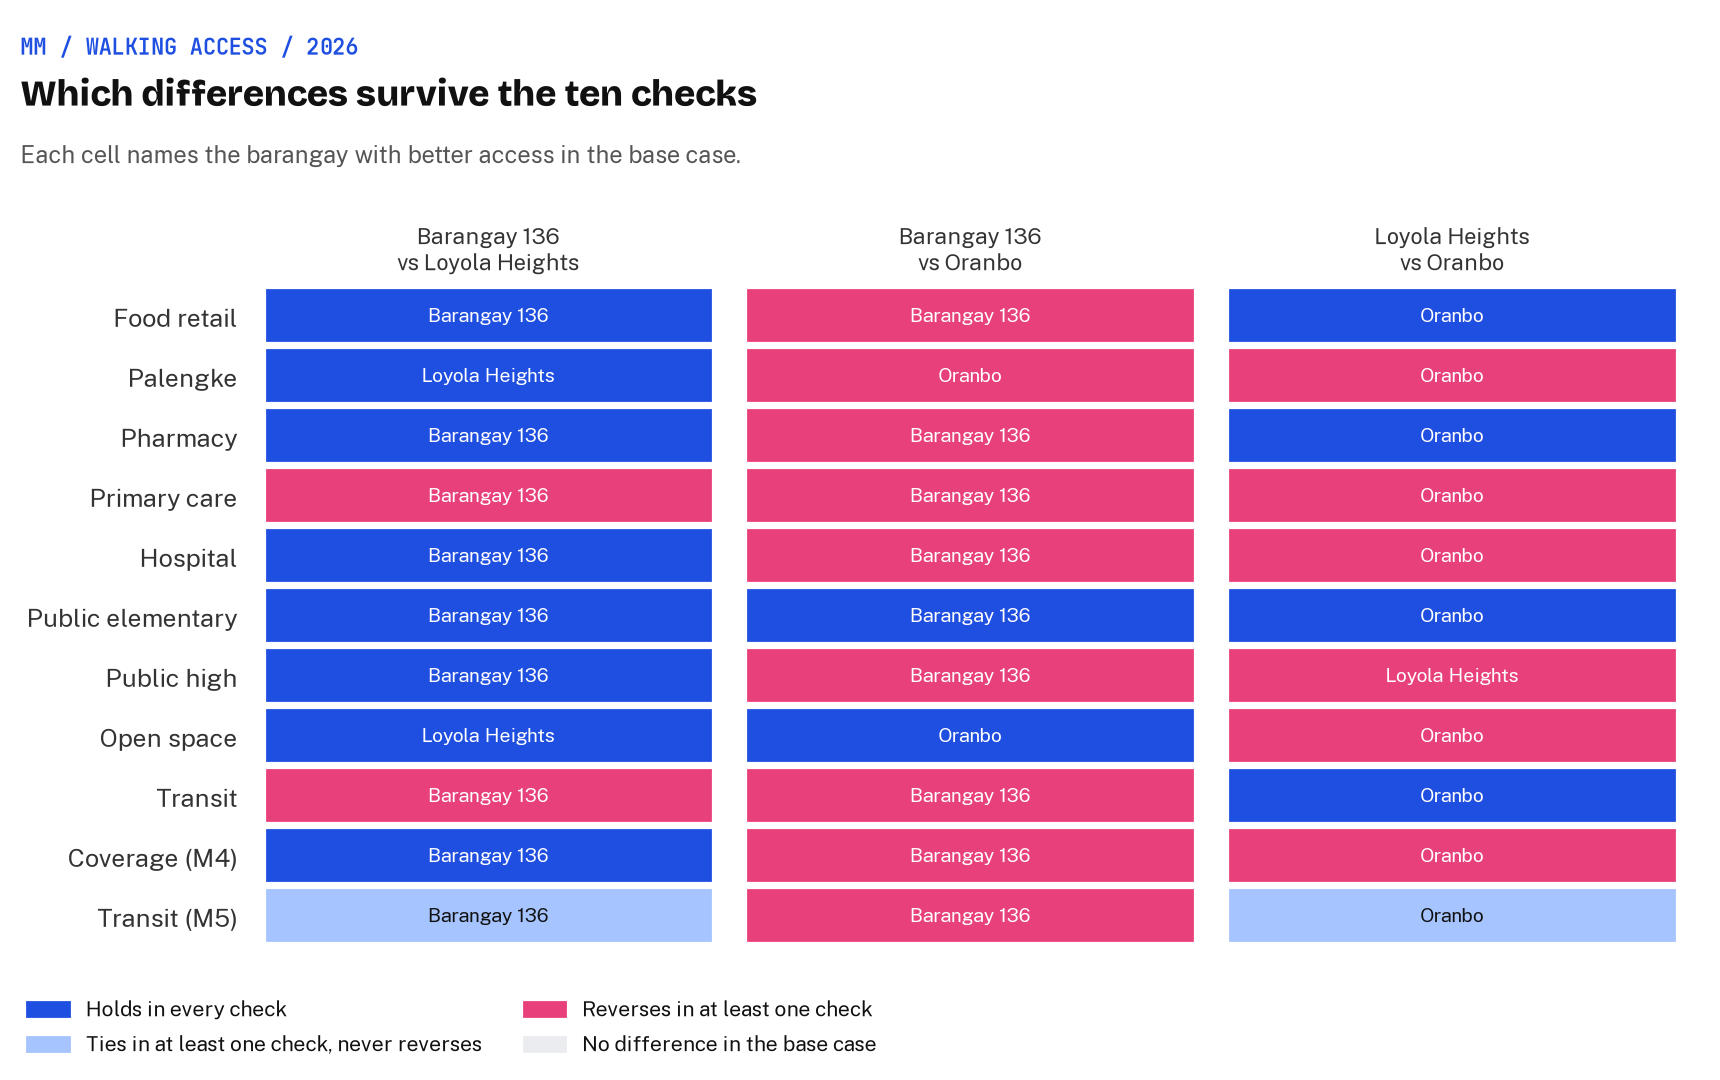

In [4]:
Image(charts.robustness_chart(r))

**Reading.** Of the 33 pairwise differences (eleven metrics for three pairs), 14 hold in every variant of every check, and two more only tie somewhere (Barangay 136 and Oranbo against Loyola Heights on transit, M5). The findings that hold:

- **Loyola Heights trails both others** for food, pharmacies and public elementary schools, and trails Barangay 136 for hospitals, public high schools and coverage (M4), and Oranbo for transit (M1).
- **Barangay 136 leads both others** for public elementary schools.
- **Barangay 136 trails both others** for open space, and trails Loyola Heights for the palengke.

Most differences between Barangay 136 and Oranbo do not hold: they reverse in the equal walk-shed check, so they say more about the barangays' very different sizes than about the places.

In [5]:
x = r.assign(variant=r.variants_that_change_it.str.split("; ")).explode("variant")
x = x[x.variant.fillna("") != ""].assign(
    check=lambda d: d.variant.str[:2], reversed=lambda d: d.variant.str.endswith("(reversed)")
)
pd.DataFrame(
    {
        "pairs_changed": x.drop_duplicates(["check", "metric", "a", "b"]).groupby("check").size(),
        "pairs_reversed": x[x.reversed].drop_duplicates(["check", "metric", "a", "b"]).groupby("check").size(),
    }
).fillna(0).astype(int)

,pairs_changed,pairs_reversed
check,,
02,1,1
03,14,11
05,5,4
06,4,4
07,7,7
08,1,1
09,1,1


**Reading.** The equal walk-shed check (03) changes 14 of the 33 pairwise orderings (reversing 11): a 10 to 20-minute walk-shed round Barangay 136's centre takes in many Tondo blocks around the one-block barangay, and the same walk round Loyola Heights' centre leaves out its furthest villages. The data choices matter less: the service source (07) changes seven, straight-line distance (05) five, origin resolution (06) four, and the time threshold (02), Overture confidence (08) and population surface (09) one each; walking speed (01) changes none. The jeepney rule (10) changes no ordering, though it lowers Oranbo's transit share from 95% to 58% and Loyola Heights' from 48% to 40%. The home lens (04) was not run here because the private home points are not on this machine.